# Task 3B & Task E Temporal Association Analysis
**Project:** Conference Popularity and Association Pattern Mining Using DBLP Dataset (2015–2025)  
**Kelompok:** 11  
**Penanggung Jawab:** Anggota 3 (Temporal Analyst & Integration Lead)

---
### Tujuan Analisis:
1. **Task 3B (Author-Year Transactional Database):** Membangun representasi transaksi di mana 1 transaksi = kombinasi 1 author pada 1 tahun tertentu, serta membandingkannya secara analitis dengan *Author-Based* (Task 3A).
2. **Task E (Temporal Association Analysis):** Menerapkan Frequent Pattern Mining & Association Rules pada **4 periode waktu**:
   - **Periode 1: 2015–2017**
   - **Periode 2: 2018–2020**
   - **Periode 3: 2021–2023**
   - **Periode 4: 2024–2025**
3. **Sintesis Lintas Periode:** Mengidentifikasi **Pola Bertahan (Stable Patterns)** dan **Pergeseran Tren Riset (Shifting Trends)**.

## 0. Import Library & Persiapan Lingkungan

In [1]:
import os
import sys
import gc
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath('../src'))
from data_loader import build_venue_label_map
from role3_temporal import (
    construct_author_year_transactions,
    run_temporal_mining,
    PERIODS,
    OUTPUT_DIR,
    DATA_PATH,
)

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.dpi'] = 130
print('Seluruh modul berhasil diimpor!')

Seluruh modul berhasil diimpor!


## 1. Memuat Dataset Bersih DBLP (`clean_inproceedings.parquet`)

In [2]:
t0 = time.perf_counter()

df = pd.read_parquet(DATA_PATH, columns=['author_id', 'year', 'venue_key', 'venue_name'])
print(f'Dataset berhasil dimuat: {len(df):,} publikasi ({time.perf_counter() - t0:.2f} detik).')
print(f'Rentang tahun: {df["year"].min()} - {df["year"].max()}')
df.head()

Dataset berhasil dimuat: 1,899,038 publikasi (2.71 detik).
Rentang tahun: 2015 - 2025


,author_id,year,venue_key,venue_name
0,"[Lucas Roquet, Fernando Fernandes dos Santos, Paolo Rech, Marcello Traiola, Olivier Sentieys, Angeliki Kritikakou]",2024,dac,DAC
1,"[Fangxin Liu, Wenbo Zhao 0005, Zongwu Wang, Yongbiao Chen, Tao Yang 0031, Zhezhi He, Xiaokang Yang 0001, Li Jiang 0002]",2022,dac,DAC
2,"[Sunwoo Ahn, Hayoon Yi, Younghan Lee, Whoi Ree Ha, Giyeol Kim, Yunheung Paek]",2020,dac,DAC
3,"[Chanwoo Park, Junghwan Park, Premkumar Vincent, Hyunbo Cho]",2024,dac,DAC
4,"[Yuan Pu 0001, Fangzhou Liu, Yu Zhang 0189, Zhuolun He, Yibo Lin, Kai-Yuan Chao, Bei Yu 0001]",2024,dac,DAC


## 2. Task 3B Konstruksi Author-Year-Based Transactional Database

Pada representasi ini:
- **Satu transaksi** = kombinasi unik satu author_id dan satu year.
- **Item** = daftar venue_key unik tempat author tersebut mempublikasikan paper pada tahun tersebut.

In [3]:
_, venue_display_map = build_venue_label_map(df)
task3b_res = construct_author_year_transactions(df, venue_display_map, OUTPUT_DIR)
display(task3b_res['stats_df'])
display(task3b_res['dist_bucket'])


TASK 3B: KONSTRUKSI AUTHOR-YEAR TRANSACTIONAL DATABASE (Vectorized)
  [Bit-Packing] 7,428,192 entri author-paper -> 6,139,541 tripel (author, year, venue) unik
                             Metrik              Nilai
      Total Transaksi (Author-Year)          3,895,225
           Total Item Unik (Venues)              4,232
Total Pasangan (Author-Year, Venue)          6,139,541
      Rata-rata Venue per Transaksi              1.576
         Median Venue per Transaksi                1.0
   Persentil 95 Venue per Transaksi                4.0
   Persentil 99 Venue per Transaksi                7.0
       Maksimum Venue per Transaksi                 92
        Transaksi 1 Venue (len = 1) 2,784,636 (71.49%)
   Transaksi Multi-Venue (len >= 2) 1,110,589 (28.51%)
    Transaksi >= 3 Venue (len >= 3)   485,151 (12.46%)
  [Task 3B] Selesai dalam 9.63 detik. Berkas CSV tersimpan.


,Metrik,Nilai
0,Total Transaksi (Author-Year),"3,895,225"
1,Total Item Unik (Venues),"4,232"
2,"Total Pasangan (Author-Year, Venue)","6,139,541"
3,Rata-rata Venue per Transaksi,1.576
4,Median Venue per Transaksi,1.0
5,Persentil 95 Venue per Transaksi,4.0
6,Persentil 99 Venue per Transaksi,7.0
7,Maksimum Venue per Transaksi,92
8,Transaksi 1 Venue (len = 1),"2,784,636 (71.49%)"
9,Transaksi Multi-Venue (len >= 2),"1,110,589 (28.51%)"


,bucket,count,pct
0,1,2784636,71.49
1,2,625438,16.06
2,3,237757,6.10
3,4,108587,2.79
4,5,55972,1.44
5,6-10,71587,1.84
6,>10,11248,0.29


### 2.0 Distribusi Jumlah Item per Transaksi (Author-Year)
Histogram memakai sumbu-y logaritmik karena mayoritas transaksi hanya berisi 1 konferensi.

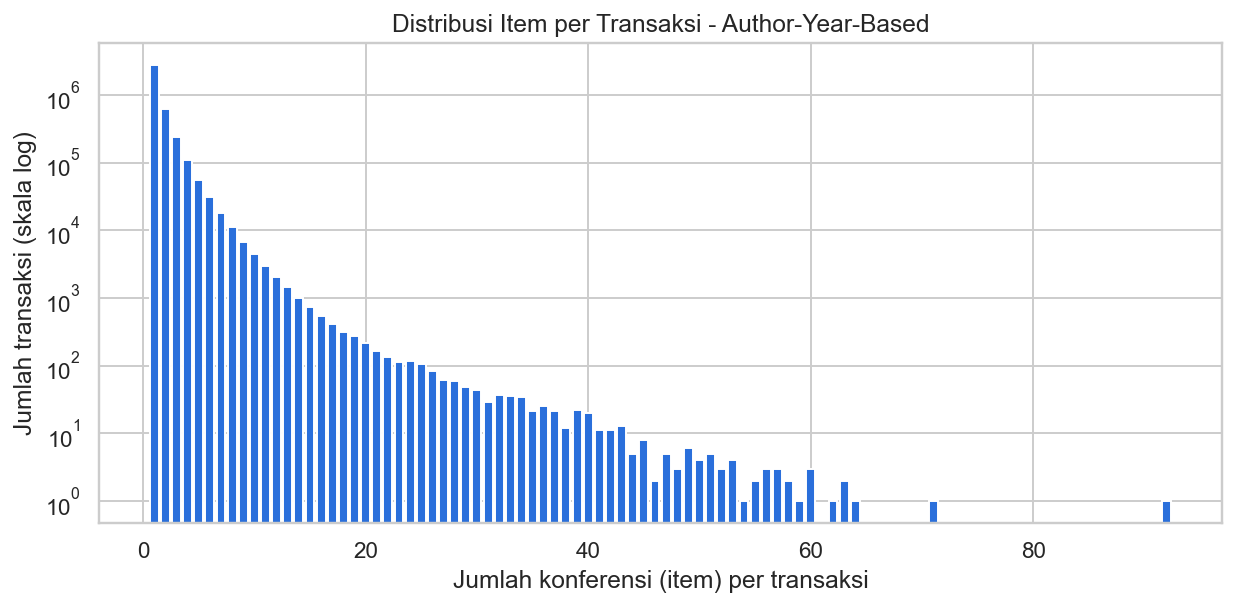

In [4]:
d = task3b_res['dist_exact']
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(d['jumlah_item'], d['jumlah_transaksi'], color='#2a6fdb')
ax.set_yscale('log')
ax.set_xlabel('Jumlah konferensi (item) per transaksi')
ax.set_ylabel('Jumlah transaksi (skala log)')
ax.set_title('Distribusi Item per Transaksi - Author-Year-Based')
plt.tight_layout(); plt.show()

### 2.0b Cross-check dengan Role 2
Jumlah transaksi dan distribusi 3B harus identik dengan kolom Author-Year-Based milik Role 2.

In [5]:
r2_path = OUTPUT_DIR.parent / 'role2' / 'task3_transaction_stats.csv'
if r2_path.is_file():
    r2 = pd.read_csv(r2_path)
    display(r2)
    n_r2 = int(str(r2.loc[r2['Metrik'].str.contains('Jumlah Transaksi'), 'Author-Year-Based'].iloc[0]).replace(',', ''))
    print('n_tx Role 3 =', task3b_res['n_tx'], '| n_tx Role 2 =', n_r2, '| COCOK' if n_r2 == task3b_res['n_tx'] else '| BEDA!')
else:
    print('File Role 2 tidak ditemukan di', r2_path, '- salin folder output/role2 ke sini lalu jalankan ulang.')

n_tx Role 3 = 3895225 | n_tx Role 2 = 3895225 | COCOK


,Metrik,Author-Based,Author-Year-Based
0,Jumlah Transaksi,"1,738,301","3,895,225"
1,Jumlah Item Unik (venue_key),"4,232","4,232"
2,Total Pasangan Transaksi-Item (NNZ),"4,597,655","6,139,541"
3,Kepadatan Matriks (%),0.0625%,0.0372%
4,Item per Transaksi — Min,1,1
5,Item per Transaksi — Kuartil 1 (P25),1.0,1.0
6,Item per Transaksi — Median (P50),1.0,1.0
7,Item per Transaksi — Rata-rata (Mean),2.645,1.576
8,Item per Transaksi — Kuartil 3 (P75),3.0,2.0
9,Item per Transaksi — Persentil 95 (P95),9.0,4.0


### 2.1 Sepuluh (10) Contoh Transaksi Author-Year
Menampilkan contoh transaksi dengan variasi panjang item (1 item, 2 item, hingga 3+ item):

In [6]:
df_examples = pd.read_csv(OUTPUT_DIR / 'task3b_author_year_examples.csv')
df_examples

,No,Author ID,Tahun,Jumlah Item,Daftar Konferensi (Names),Daftar Konferensi (Keys)
0,1,Bryan C. K. Ng,2016,11,"CCGRID, eScience, HPCC/SmartCity/DSS, UbiComp/ISWC Adjunct, ICCCN, ICECCS, IPCCC, MASCOTS, MSWiM, NOMS, UCC","ccgrid, eScience, hpcc, huc, icccn, iceccs, ipccc, mascots, mswim, noms, ucc"
1,2,Xiaoxiao Guo,2018,7,"AAAI, EMNLP, ICLR, ICWSM, IJCAI, NAACL-HLT, NeurIPS","aaai, emnlp, iclr, icwsm, ijcai, naacl, nips"
2,3,Chengchao Shen,2018,5,"CSAE, CVPR, ECCV, ICONIP, W4A","csae, cvpr, eccv, iconip, w4a"
3,4,Jiankun Zhang,2022,4,"GLOBECOM, PIMRC, VTC Fall, WCNC [wcnc]","globecom, pimrc, vtc, wcnc"
4,5,Dana Fisman,2022,4,"ATVA, CPM, CSL, FoSSaCS","atva, cpm, csl, fossacs"
5,6,Byungjeon Kang,2019,2,"ASCC, EMBC","ascc, embc"
6,7,Jennie Si,2022,2,"ICRA, NeurIPS","icra, nips"
7,8,Vibhoothi,2022,2,"AVSS, ICIP","avss, icip"
8,9,Ghiles Ziat,2018,1,CP,cp
9,10,Liang Xie 0013,2024,1,DCC,dcc


## 3. Task E Temporal Association Analysis (4 Periode Waktu)

Kita mengeksekusi algoritma **FP-Growth** dan membangkitkan **Association Rules** pada 4 periode temporal berbasis *Author-Year-Based Transactional Database*:
- **P1:** `2015–2017`
- **P2:** `2018–2020`
- **P3:** `2021–2023`
- **P4:** `2024–2025` *(catatan: data 2025 parsial per snapshot `dblp-2025-12-01`)*

**Justifikasi Parameter (`min_support = 0,05%`, `min_confidence = 25%`):**
Berbeda dengan representasi *Author-Based* (agregasi 11 tahun, Task 5 memakai *min_confidence* 50%), representasi *Author-Year-Based* jauh lebih *sparse* (`71,49%` transaksi hanya 1 item). Pada uji sensitivitas (`taskE_threshold_sensitivity.csv`), ambang `min_support = 0,08%` dan `min_confidence = 50%` menghasilkan `0` rules di P2 (`2018–2020`) dan `0` pola bertahan lintas periode. Penyesuaian ke `min_support = 0,05%` dan `min_confidence = 25%` menghasilkan aturan di **keempat periode** (`14`, `28`, `82`, `281` rules) beserta **3 pola bertahan di seluruh 4 periode** dan **15 pola bertahan di $\ge 3$ periode**, sembari tetap mempertahankan nilai *Lift* sangat tinggi (`7,6` hingga `>120`).

In [7]:
temporal_res = run_temporal_mining(df, venue_display_map, OUTPUT_DIR)


TASK E: TEMPORAL ASSOCIATION ANALYSIS (4 PERIODE)

>>> Mengeksekusi Periode P1: 2015-2017 ...
  [P1] Transaksi Author-Year: 921,433 | Multi-Venue (>=2): 270,247 (29.3%)
  [P1] 857 frequent itemsets | 14 rules (conf>=25%) -> taskE_rules_p1_2015_2017.csv
  [P1] Selesai dalam 4.80 detik.

>>> Mengeksekusi Periode P2: 2018-2020 ...
  [P2] Transaksi Author-Year: 1,078,007 | Multi-Venue (>=2): 304,631 (28.3%)
  [P2] 812 frequent itemsets | 28 rules (conf>=25%) -> taskE_rules_p2_2018_2020.csv
  [P2] Selesai dalam 5.05 detik.

>>> Mengeksekusi Periode P3: 2021-2023 ...
  [P3] Transaksi Author-Year: 1,185,772 | Multi-Venue (>=2): 334,641 (28.2%)
  [P3] 873 frequent itemsets | 82 rules (conf>=25%) -> taskE_rules_p3_2021_2023.csv
  [P3] Selesai dalam 6.05 detik.

>>> Mengeksekusi Periode P4: 2024-2025 ...
  [P4] Transaksi Author-Year: 710,013 | Multi-Venue (>=2): 201,070 (28.3%)
  [P4] 918 frequent itemsets | 281 rules (conf>=25%) -> taskE_rules_p4_2024_2025.csv
  [P4] Selesai dalam 3.65 detik.


### 3.0 Ringkasan per Periode
Jumlah transaksi, transaksi multi-venue, threshold efektif, jumlah itemsets (per ukuran), dan jumlah rules.

In [8]:
display(pd.read_csv(OUTPUT_DIR / 'taskE_period_summary.csv'))

,period,label,n_papers,n_tx,n_multi,pct_multi,min_abs_count,eff_min_support_pct,n_itemsets,n_1,n_2,n_3,n_4plus,n_rules,runtime_s
0,P1,2015-2017,491471,921433,270247,29.33,461,0.0500,857,815,40,2,0,14,4.80
1,P2,2018-2020,537085,1078007,304631,28.26,540,0.0501,812,731,76,5,0,28,5.05
2,P3,2021-2023,556604,1185772,334641,28.22,593,0.0500,873,704,140,29,0,82,6.05
3,P4,2024-2025,313878,710013,201070,28.32,356,0.0501,918,574,223,105,16,281,3.65


### 3.0b Frequent Itemsets per Periode (Top 10 per ukuran)
Support dihitung terhadap SELURUH transaksi author-year pada periode tersebut.

In [9]:
for p in PERIODS:
    pid = p['id']; f = pd.read_csv(OUTPUT_DIR / f"taskE_itemsets_{pid.lower()}_{p['years'][0]}_{p['years'][1]}.csv")
    print(f"\n{'='*70}\n{pid} {p['label']} | total itemsets = {len(f):,}\n{'='*70}")
    for L in [1, 2, 3]:
        sub = f[f['length'] == L].head(10)
        if not sub.empty:
            print(f'--- Top {len(sub)} {L}-itemsets ---')
            display(sub[['count', 'support', 'itemsets_names']])


P1 2015-2017 | total itemsets = 857
--- Top 10 1-itemsets ---
--- Top 10 2-itemsets ---
--- Top 2 3-itemsets ---

P2 2018-2020 | total itemsets = 812
--- Top 10 1-itemsets ---
--- Top 10 2-itemsets ---
--- Top 5 3-itemsets ---

P3 2021-2023 | total itemsets = 873
--- Top 10 1-itemsets ---
--- Top 10 2-itemsets ---
--- Top 10 3-itemsets ---

P4 2024-2025 | total itemsets = 918
--- Top 10 1-itemsets ---
--- Top 10 2-itemsets ---
--- Top 10 3-itemsets ---


,count,support,itemsets_names
0,17284,0.018758,{EMBC}
1,13777,0.014952,{IGARSS}
2,12210,0.013251,{HCI}
3,12000,0.013023,{ICC [icc]}
4,10536,0.011434,{GLOBECOM}
5,10007,0.010860,{IECON}
6,9921,0.010767,{ICASSP}
7,9374,0.010173,{CHI}
8,8557,0.009287,{VTC Fall}
9,8525,0.009252,{IROS}


,count,support,itemsets_names
72,2961,0.003213,"{GLOBECOM, ICC [icc]}"
133,1880,0.002040,"{ACC, CDC}"
142,1782,0.001934,"{ICRA, IROS}"
151,1718,0.001864,"{ECOC, OFC}"
182,1544,0.001676,"{ICC [icc], VTC Fall}"
183,1543,0.001675,"{GLOBECOM, VTC Fall}"
197,1450,0.001574,"{AAAI, IJCAI}"
222,1297,0.001408,"{ICASSP, INTERSPEECH}"
246,1225,0.001329,"{CVPR, ICCV}"
338,959,0.001041,"{ICC [icc], WCNC [wcnc]}"


,count,support,itemsets_names
511,740,0.000803,"{GLOBECOM, ICC [icc], VTC Fall}"
831,477,0.000518,"{GLOBECOM, ICC [icc], WCNC [wcnc]}"


,count,support,itemsets_names
0,19197,0.017808,{IGARSS}
1,17513,0.016246,{EMBC}
2,17215,0.015969,{CVPR}
3,15153,0.014056,{AAAI}
4,14327,0.013290,{NeurIPS}
5,14163,0.013138,{ICASSP}
6,14080,0.013061,{HCI}
7,12402,0.011505,{CHI}
8,11573,0.010736,{MICCAI}
9,11527,0.010693,{GLOBECOM}


,count,support,itemsets_names
83,2986,0.002770,"{CVPR, ECCV}"
100,2727,0.002530,"{GLOBECOM, ICC [icc]}"
105,2610,0.002421,"{ICML, NeurIPS}"
134,2217,0.002057,"{ICRA, IROS}"
138,2182,0.002024,"{AAAI, IJCAI}"
141,2174,0.002017,"{ACL, EMNLP}"
161,1949,0.001808,"{ICASSP, INTERSPEECH}"
165,1923,0.001784,"{ICLR, NeurIPS}"
178,1797,0.001667,"{CVPR, NeurIPS}"
181,1787,0.001658,"{AAAI, CVPR}"


... (3 outputs left out)

,count,support,itemsets_names
189,1954,0.001648,"{ICLR, ICML, NeurIPS}"
229,1661,0.001401,"{CVPR, ICCV, NeurIPS}"
328,1272,0.001073,"{CVPR, ICLR, NeurIPS}"
373,1170,0.000987,"{AAAI, CVPR, NeurIPS}"
404,1088,0.000918,"{AAAI, CVPR, ICCV}"
410,1082,0.000912,"{AAAI, ICML, NeurIPS}"
422,1062,0.000896,"{AAAI, ACL, EMNLP}"
465,995,0.000839,"{CVPR, ICML, NeurIPS}"
467,989,0.000834,"{ACL, EMNLP, NeurIPS}"
482,975,0.000822,"{AAAI, ICLR, NeurIPS}"


,count,support,itemsets_names
0,30357,0.042756,{CVPR}
1,25676,0.036163,{AAAI}
2,25327,0.035671,{ICLR}
3,21702,0.030566,{ICASSP}
4,20941,0.029494,{ACL}
5,18590,0.026183,{NeurIPS}
6,14205,0.020007,{CHI}
7,13714,0.019315,{ICRA}
8,13495,0.019007,{IJCNN}
9,13178,0.018560,{MICCAI}


,count,support,itemsets_names
34,4757,0.006700,"{AAAI, CVPR}"
36,4505,0.006345,"{CVPR, ICLR}"
43,3872,0.005453,"{CVPR, ECCV}"
51,3710,0.005225,"{ICML, NeurIPS}"
53,3697,0.005207,"{ACL, ICLR}"
54,3581,0.005044,"{AAAI, ICLR}"
55,3551,0.005001,"{ICLR, NeurIPS}"
60,3315,0.004669,"{ACL, NAACL-HLT}"
61,3228,0.004546,"{CVPR, NeurIPS}"
62,3155,0.004444,"{AAAI, ACL}"


,count,support,itemsets_names
150,1543,0.002173,"{CVPR, ECCV, NeurIPS}"
152,1539,0.002168,"{ICLR, ICML, NeurIPS}"
178,1402,0.001975,"{AAAI, CVPR, ICLR}"
243,1109,0.001562,"{AAAI, ACL, ICLR}"
250,1076,0.001515,"{ACL, ICLR, NAACL-HLT}"
273,1000,0.001408,"{AAAI, CVPR, ICASSP}"
285,979,0.001379,"{CVPR, ICLR, NeurIPS}"
286,973,0.001370,"{ACL, CVPR, ICLR}"
298,936,0.001318,"{AAAI, CVPR, NeurIPS}"
299,934,0.001315,"{AAAI, CVPR, ECCV}"


### 3.1 Top 10 Association Rules per Periode (Berdasarkan Nilai Lift Tertinggi)

In [10]:
for p_id in ['P1', 'P2', 'P3', 'P4']:
    info = temporal_res[p_id]
    print(f"\n{'='*75}")
    print(f"TOP 10 RULES PERIODE {p_id}: {info['label']} (N_Rules = {info['n_rules']:,})")
    print(f"{'='*75}")
    top10 = info['top10_lift']
    if not top10.empty:
        display(top10[['rule_names', 'support', 'confidence', 'lift']].head(10))
    else:
        print('Tidak ada rule yang memenuhi kriteria.')


TOP 10 RULES PERIODE P1: 2015-2017 (N_Rules = 14)

TOP 10 RULES PERIODE P2: 2018-2020 (N_Rules = 28)

TOP 10 RULES PERIODE P3: 2021-2023 (N_Rules = 82)

TOP 10 RULES PERIODE P4: 2024-2025 (N_Rules = 281)


,rule_names,support,confidence,lift
0,{EMNLP} -> {ACL},0.000794,0.255497,72.728983
1,{ECOC} -> {OFC},0.001864,0.514834,59.603561
2,{ICML} -> {NeurIPS},0.001011,0.294843,55.728911
3,"{ICC [icc], WCNC [wcnc]} -> {GLOBECOM}",0.000518,0.497393,43.499851
4,"{ICC [icc], VTC Fall} -> {GLOBECOM}",0.000803,0.479275,41.915285
5,{ICCV} -> {CVPR},0.001329,0.349900,41.197219
6,"{GLOBECOM, WCNC [wcnc]} -> {ICC [icc]}",0.000518,0.515119,39.553954
7,"{GLOBECOM, VTC Fall} -> {ICC [icc]}",0.000803,0.479585,36.825471
8,{ECCV} -> {CVPR},0.000623,0.289023,34.029578
9,{ECC [eucc]} -> {CDC},0.000774,0.272034,33.200094


,rule_names,support,confidence,lift
0,"{AAAI, EMNLP} -> {ACL}",0.000601,0.461210,75.779236
1,"{AAAI, ACL} -> {EMNLP}",0.000601,0.580125,71.627439
2,{ECOC} -> {OFC},0.001447,0.473014,63.147040
3,"{ICLR, NeurIPS} -> {ICML}",0.000718,0.402496,55.705946
4,"{ICML, NeurIPS} -> {ICLR}",0.000718,0.296552,51.603686
5,{OECC/PSC} -> {OFC},0.000569,0.335890,44.841141
6,"{GLOBECOM, VTC Fall} -> {ICC [icc]}",0.000507,0.450948,44.213294
7,{NAACL-HLT} -> {ACL},0.000685,0.265181,43.570716
8,"{ICLR, ICML} -> {NeurIPS}",0.000718,0.571640,43.011899
9,"{ICC [icc], VTC Fall} -> {GLOBECOM}",0.000507,0.457741,42.807977


,rule_names,support,confidence,lift
0,{ECOC} -> {OFC},0.000506,0.480384,69.619440
1,{ASRU} -> {INTERSPEECH},0.000522,0.437456,48.669814
2,"{ICC [icc], VTC Fall} -> {GLOBECOM}",0.000552,0.525682,46.608286
3,"{EACL, EMNLP} -> {ACL}",0.000568,0.593833,46.140493
4,"{GLOBECOM, VTC Fall} -> {ICC [icc]}",0.000552,0.436376,43.974007
5,"{ACL, NAACL-HLT} -> {EMNLP}",0.000752,0.635780,42.735144
6,"{ACL, EACL} -> {EMNLP}",0.000568,0.621198,41.754967
7,"{EMNLP, NAACL-HLT} -> {ACL}",0.000752,0.518605,40.295320
8,"{AAAI, EMNLP} -> {ACL}",0.000896,0.516035,40.095658
9,"{EMNLP, ICLR} -> {ACL}",0.000552,0.506584,39.361325


,rule_names,support,confidence,lift
0,{CLEF (Working Notes)} -> {ECIR},0.000524,0.286154,124.112982
1,"{CVPR, ICML} -> {ECCV, ICLR}",0.000513,0.260558,123.911459
2,"{EMNLP, ICLR} -> {ACL, NeurIPS}",0.000535,0.291188,116.674425
3,"{ACM Multimedia, CVPR} -> {AAAI, ECCV}",0.000518,0.256804,110.105141
4,"{ECCV, ICLR} -> {CVPR, NeurIPS}",0.000834,0.396517,87.215701
5,"{ECCV, ICML} -> {CVPR, NeurIPS}",0.000638,0.391192,86.044362
6,"{CVPR, ICML} -> {ECCV, NeurIPS}",0.000638,0.324266,85.588579
7,"{ACM Multimedia, ECCV} -> {CVPR, NeurIPS}",0.000539,0.334498,73.574287
8,"{ACM Multimedia, CVPR} -> {AAAI, NeurIPS}",0.000548,0.271458,72.814148
9,"{AAAI, ECCV} -> {CVPR, NeurIPS}",0.000768,0.329106,72.388394


## 4. Analisis Komparatif: Pola Bertahan (Stable) vs Pergeseran Tren (Shifting)

### 4.1 Pola Bertahan (Stable Patterns)
Aturan asosiasi yang selalu muncul secara konsisten di hampir seluruh periode pengamatan merepresentasikan konferensi inti dalam satu rumpun keilmuan yang tak terpisahkan:

In [11]:
stable_df = pd.read_csv(OUTPUT_DIR / 'taskE_stable_patterns_lift.csv', index_col=0)
print(f'Total Pola Bertahan Terdeteksi: {len(stable_df)}')
display(stable_df.head(12))

Total Pola Bertahan Terdeteksi: 15


,2015-2017,2018-2020,2021-2023,2024-2025,n_periods,mean_lift
rule_names,,,,,,
{UIST} -> {CHI},31.467497,30.365319,27.623062,19.127014,4,27.145723
{ICML} -> {NeurIPS},55.728911,25.213035,13.216480,14.032190,4,27.047654
{ECCV} -> {CVPR},34.029578,19.142502,13.418264,7.589786,4,18.545033
{ECOC} -> {OFC},59.603561,63.147040,69.619440,NaN,3,64.123347
"{AAAI, EMNLP} -> {ACL}",NaN,75.779236,40.095658,16.199247,3,44.024714
"{ICC [icc], VTC Fall} -> {GLOBECOM}",41.915285,42.807977,46.608286,NaN,3,43.777183
"{GLOBECOM, VTC Fall} -> {ICC [icc]}",36.825471,44.213294,43.974007,NaN,3,41.670924
"{ICLR, NeurIPS} -> {ICML}",NaN,55.705946,30.920439,30.473258,3,39.033214
{EMNLP} -> {ACL},72.728983,NaN,22.859270,9.187769,3,34.925341


### 4.2 Pergeseran Tren Riset Pasca-2018 (Shifting Trends)
Aturan asosiasi baru yang muncul pasca-2018 (tidak ada di Periode 2015–2017), merefleksikan meledaknya era Transformer, kemunculan pesat konferensi seperti ICLR, dan kolaborasi lintas rumpun:

In [12]:
shifting_df = pd.read_csv(OUTPUT_DIR / 'taskE_shifting_trends.csv')
print(f'Total Aturan Pergeseran Baru Pasca-2018: {len(shifting_df)}')
display(shifting_df.head(10))

Total Aturan Pergeseran Baru Pasca-2018: 30


,rule_names,period_label,count,support,confidence,lift,n_periods,category
0,{CLEF (Working Notes)} -> {ECIR},2024-2025,372,0.000524,0.286154,124.112982,1,emerging
1,"{CVPR, ICML} -> {ECCV, ICLR}",2024-2025,364,0.000513,0.260558,123.911459,1,emerging
2,"{EMNLP, ICLR} -> {ACL, NeurIPS}",2024-2025,380,0.000535,0.291188,116.674425,1,emerging
3,"{ACM Multimedia, CVPR} -> {AAAI, ECCV}",2024-2025,368,0.000518,0.256804,110.105141,1,emerging
4,"{ECCV, ICLR} -> {CVPR, NeurIPS}",2024-2025,592,0.000834,0.396517,87.215701,1,emerging
5,"{ECCV, ICML} -> {CVPR, NeurIPS}",2024-2025,453,0.000638,0.391192,86.044362,1,emerging
6,"{CVPR, ICML} -> {ECCV, NeurIPS}",2024-2025,453,0.000638,0.324266,85.588579,1,emerging
7,"{AAAI, EMNLP} -> {ACL}",2018-2020,648,0.000601,0.461210,75.779236,3,stable_3
8,"{ACM Multimedia, ECCV} -> {CVPR, NeurIPS}",2024-2025,383,0.000539,0.334498,73.574287,1,emerging
9,"{ACM Multimedia, CVPR} -> {AAAI, NeurIPS}",2024-2025,389,0.000548,0.271458,72.814148,1,emerging


### 4.2b Pola yang Menghilang (ada di 2015-2017, tidak ada di 2024-2025)

In [13]:
fading_df = pd.read_csv(OUTPUT_DIR / 'taskE_fading_patterns.csv')
print(f'Total rule memudar (top 30 ditampilkan): {len(fading_df)}')
display(fading_df.head(30))

Total rule memudar (top 30 ditampilkan): 10


,rule_keys,rule_names,lift_P1,support_P1,n_periods,last_period
0,{ecoc} -> {ofc},{ECOC} -> {OFC},59.603561,0.001864,3,P3
1,"{icc, wcnc} -> {globecom}","{ICC [icc], WCNC [wcnc]} -> {GLOBECOM}",43.499851,0.000518,1,P1
2,"{icc, vtc} -> {globecom}","{ICC [icc], VTC Fall} -> {GLOBECOM}",41.915285,0.000803,3,P3
3,{iccv} -> {cvpr},{ICCV} -> {CVPR},41.197219,0.001329,3,P3
4,"{globecom, wcnc} -> {icc}","{GLOBECOM, WCNC [wcnc]} -> {ICC [icc]}",39.553954,0.000518,1,P1
5,"{globecom, vtc} -> {icc}","{GLOBECOM, VTC Fall} -> {ICC [icc]}",36.825471,0.000803,3,P3
6,{eucc} -> {cdc},{ECC [eucc]} -> {CDC},33.200094,0.000774,1,P1
7,{amcc} -> {cdc},{ACC} -> {CDC},31.560236,0.002040,1,P1
8,{cscw} -> {chi},{CSCW Companion} -> {CHI},26.888688,0.000725,1,P1
9,{globecom} -> {icc},{GLOBECOM} -> {ICC [icc]},21.579688,0.003213,1,P1


### 4.2c Kategori Rule & Overlap Antarperiode
`stable_all` = muncul di 4 periode, `stable_3` = 3 periode, `emerging` = baru setelah P1 dan masih ada di P4, `fading` = ada di P1 tapi hilang di P4, `transient` = lainnya.

In [14]:
pres = pd.read_csv(OUTPUT_DIR / 'taskE_rule_presence.csv')
display(pres['category'].value_counts().rename('jumlah_rule').to_frame())
print('Overlap Jaccard antar-periode (set rule):')
display(pd.read_csv(OUTPUT_DIR / 'taskE_rule_overlap_jaccard.csv', index_col=0))

Overlap Jaccard antar-periode (set rule):


,jumlah_rule
category,
emerging,270
transient,43
stable_3,12
fading,6
stable_all,3


,P1,P2,P3,P4
P1,1.0000,0.2000,0.0909,0.0137
P2,0.2000,1.0000,0.2500,0.0404
P3,0.0909,0.2500,1.0000,0.1204
P4,0.0137,0.0404,0.1204,1.0000


### 4.2d Perubahan Popularitas Venue Antarperiode
Support venue dihitung eksak dari seluruh transaksi. Catatan: data 2025 belum lengkap (snapshot Desember 2025), sehingga periode 2024-2025 perlu diinterpretasi hati-hati.

In [15]:
vs = pd.read_csv(OUTPUT_DIR / 'taskE_venue_support_by_period.csv')

print('Top 10 venue dengan kenaikan support terbesar (P-akhir vs P-awal):')
display(vs.nlargest(10, 'delta_pp_last_vs_first')[['venue_name'] + [c for c in vs.columns if c.startswith('support_pct_')] + ['delta_pp_last_vs_first']])

print('Top 10 venue dengan penurunan support terbesar:')
display(vs.nsmallest(10, 'delta_pp_last_vs_first')[['venue_name'] + [c for c in vs.columns if c.startswith('support_pct_')] + ['delta_pp_last_vs_first']])

Top 10 venue dengan kenaikan support terbesar (P-akhir vs P-awal):
Top 10 venue dengan penurunan support terbesar:


,venue_name,support_pct_P1,support_pct_P2,support_pct_P3,support_pct_P4,delta_pp_last_vs_first
2,ICLR,0.100604,0.574672,1.168943,3.567118,3.466514
0,CVPR,0.849329,1.596928,2.451652,4.275556,3.426226
1,AAAI,0.790508,1.405649,1.840910,3.616272,2.825764
4,ACL,0.351301,0.608623,1.287010,2.949383,2.598082
5,NeurIPS,0.529067,1.329027,2.765456,2.618262,2.089195
3,ICASSP,1.076692,1.313813,1.782552,3.056564,1.979871
10,ECCV,0.215534,0.906117,0.663450,1.680533,1.464999
11,COLING,0.137829,0.328755,0.234868,1.500818,1.362989
8,IJCNN,0.598850,0.803984,0.923702,1.900669,1.301820
14,NAACL-HLT,0.167999,0.258162,0.406318,1.412791,1.244792


,venue_name,support_pct_P1,support_pct_P2,support_pct_P3,support_pct_P4,delta_pp_last_vs_first
31,EMBC,1.875774,1.624572,1.351272,0.793507,-1.082267
3948,AMIA,0.785407,0.722444,0.489048,0.000000,-0.785407
54,IECON,1.086026,0.829401,0.769710,0.427598,-0.658428
77,ICIP,0.894585,0.753706,0.689762,0.301825,-0.592759
3536,CogSci,0.553160,0.520590,0.547997,0.000000,-0.553160
35,GLOBECOM,1.143436,1.069288,1.127873,0.614918,-0.528518
57,CDC,0.819376,0.652593,0.633258,0.396753,-0.422623
2483,ICIA [icinfa],0.387766,0.084508,0.000000,0.000000,-0.387766
2592,ICCV,0.379952,0.336269,1.213893,0.000000,-0.379952
3845,SSCI,0.366060,0.321798,0.231073,0.000000,-0.366060


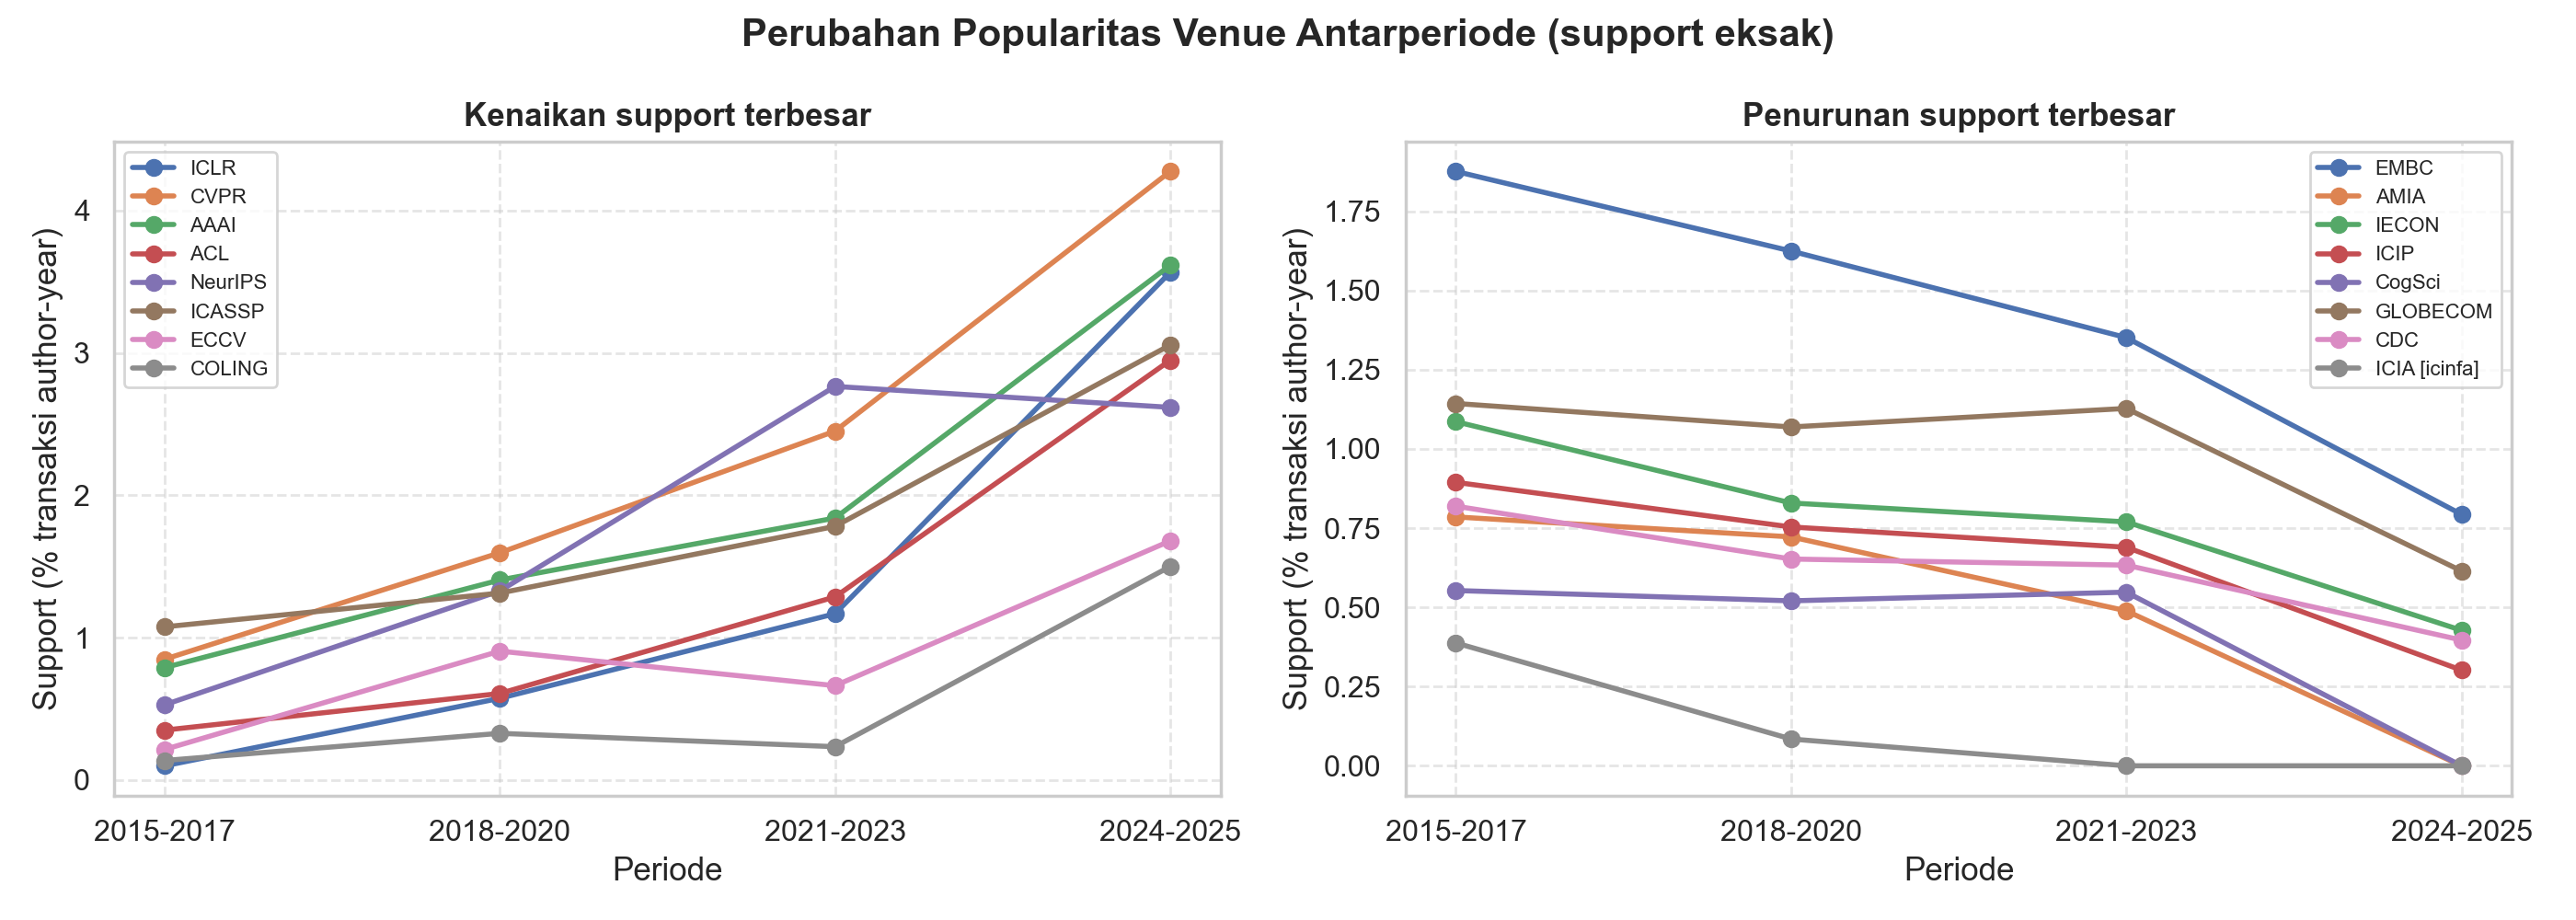

In [16]:
from IPython.display import Image
Image(filename=str(OUTPUT_DIR / 'taskE_venue_support_trend.png'))

### 4.3 Visualisasi Dinamika Asosiasi Lintas Periode

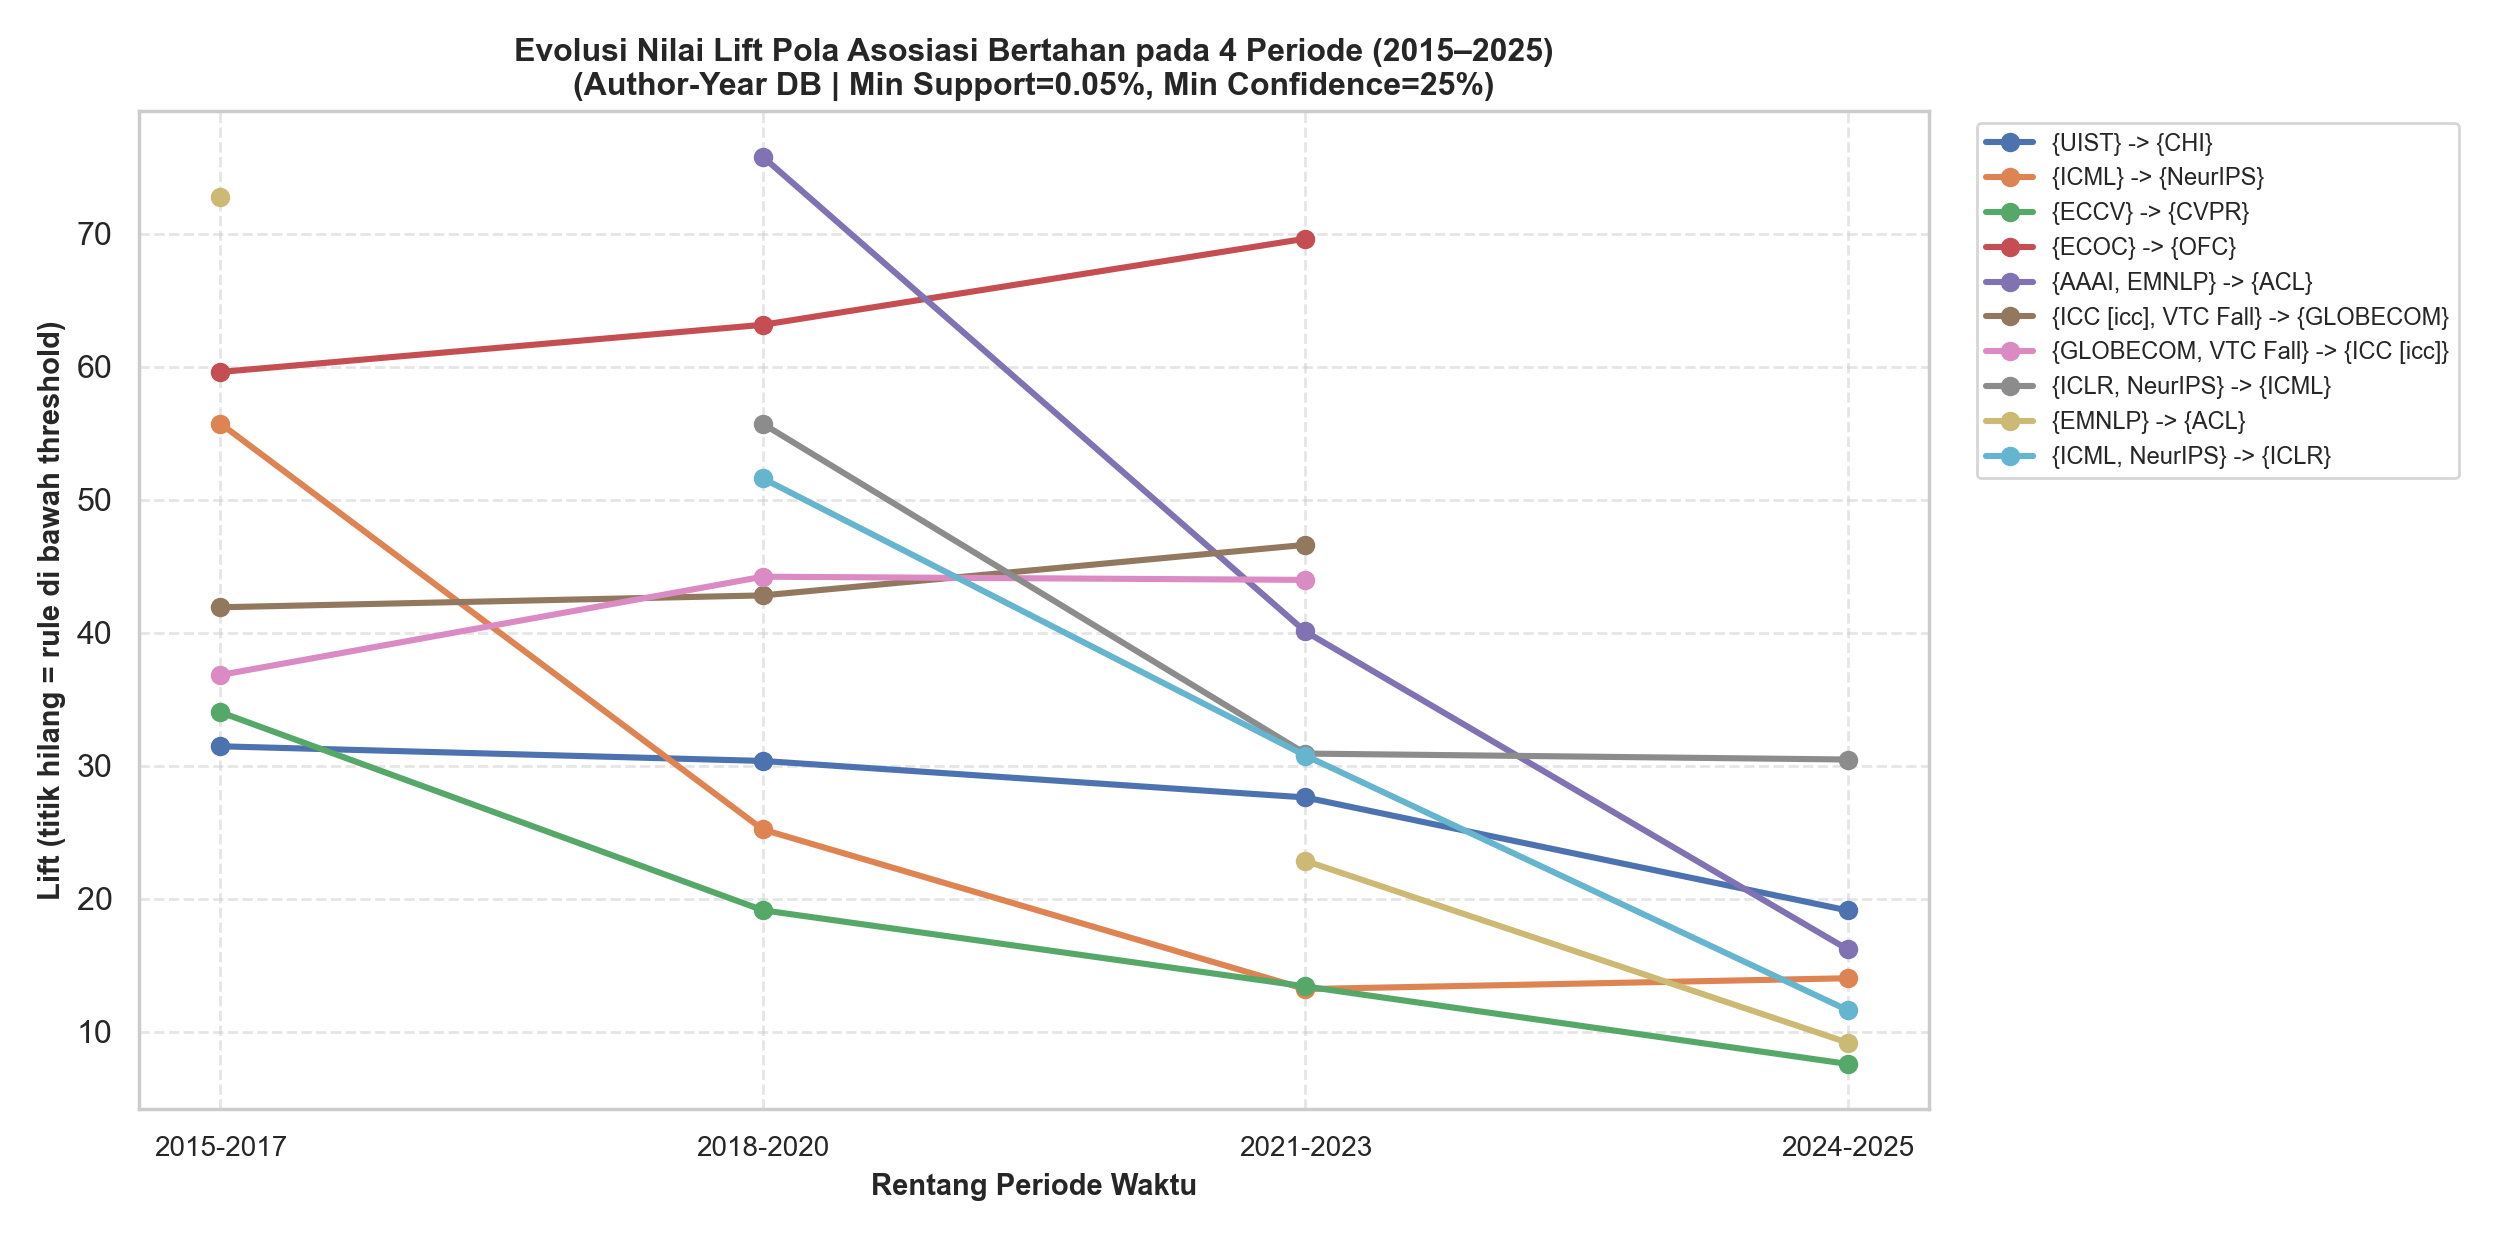

In [17]:
from IPython.display import Image
Image(filename=str(OUTPUT_DIR / 'taskE_temporal_comparison.png'))

## 5. Interpretasi & Sintesis Temporal (Task E & Kontribusi Bagian H)

### 1. Perbedaan Pola Author-Based vs Author-Year-Based
- **Ukuran & Kepadatan:** *Author-Based* terdiri dari **1.738.301 transaksi** (41,32% multi-item, rata-rata `2,645` venue/author), sedangkan *Author-Year-Based* terdiri dari **3.895.225 transaksi** (hanya 28,51% multi-item; **71,49%** hanya 1 venue, rata-rata `1,576` venue/transaksi).
- **Implikasi Pola Asosiasi:** *Author-Based* menangkap afinitas karir jangka panjang serta pasangan konferensi **bienial berselang tahun** (seperti `{ICCV, ECCV}` yang terjadi di tahun ganjil vs genap). Sebaliknya, *Author-Year-Based* hanya menangkap ko-kejadian **di tahun kalender yang sama** sehingga *confidence* antar-pasangan lebih rendah, tetapi mampu memperlihatkan evolusi tren dari waktu ke waktu.

### 2. Pola Asosiasi yang Bertahan (*Stable Patterns*)
Pada parameter `min_support = 0,05%` dan `min_confidence = 25%`, teridentifikasi **15 pola bertahan ($\ge 3$ periode)** dengan **3 pola bertahan konsisten di seluruh 4/4 periode (2015–2025)**:
1. **`{UIST} -> {CHI}`** (*Human-Computer Interaction*): Lift `31,47` (P1) $\rightarrow$ `30,37` (P2) $\rightarrow$ `27,62` (P3) $\rightarrow$ `19,13` (P4) — rata-rata Lift **27,15**.
2. **`{ICML} -> {NeurIPS}`** (*Machine Learning*): Lift `55,73` $\rightarrow$ `25,21` $\rightarrow$ `13,22` $\rightarrow$ `14,03` — rata-rata Lift **27,05**.
3. **`{ECCV} -> {CVPR}`** (*Computer Vision*): Lift `34,03` $\rightarrow$ `19,14` $\rightarrow$ `13,42` $\rightarrow$ `7,59` — rata-rata Lift **18,55**.

Selain itu, **12 pola** bertahan di 3 dari 4 periode (`stable_3`), antara lain:
- **Komunikasi Optik & Nirkabel (P1–P3):** `{ECOC} -> {OFC}` (Lift `59,60 -> 63,15 -> 69,62`), `{ICC [icc], VTC Fall} -> {GLOBECOM}` (`41,92 -> 42,81 -> 46,61`), dan `{GLOBECOM, VTC Fall} -> {ICC [icc]}` (`36,83 -> 44,21 -> 43,97`).
- **Deep Learning & NLP pasca-2018 (P2–P4):** `{AAAI, EMNLP} -> {ACL}` (`75,78 -> 40,10 -> 16,20`), `{ICLR, NeurIPS} -> {ICML}` (`55,71 -> 30,92 -> 30,47`), dan `{ICML, NeurIPS} -> {ICLR}` (`51,60 -> 30,77 -> 11,63`).

*Fenomena menarik:* Lift `{ICML} -> {NeurIPS}` dan `{ECCV} -> {CVPR}` menurun secara bertahap meski volume ko-publikasinya melonjak drastis, karena pertumbuhan eksponensial popularitas global `NeurIPS` dan `CVPR` memperbesar penyebut $P(B)$ pada rumus Lift.

### 3. Pergeseran Tren (*Emerging*, *Fading*, & Perubahan Popularitas Venue)
- **Aturan Baru (*Emerging* — 270 rules):** Terjadi lonjakan jumlah aturan dari `14` (P1) $\rightarrow$ `28` (P2) $\rightarrow$ `82` (P3) $\rightarrow$ `281` (P4). Setelah 2017 muncul dominasi kuat `ICLR`, integrasi lintas-disiplin AI/Vision/NLP/Multimedia (mis. `{CVPR, ICML} -> {ECCV, ICLR}` Lift `123,91`; `{EMNLP, ICLR} -> {ACL, NeurIPS}` Lift `116,67`; `{ACM Multimedia, CVPR} -> {AAAI, ECCV}` Lift `110,11`), serta aturan IR `{CLEF (Working Notes)} -> {ECIR}` (Lift `124,11`).
- **Pola yang Memudar dari P1 ke P4 (*Fading* — 10 rules muncul di P1 namun absen di P4):** Didominasi rumpun Sistem Kendali & Telekomunikasi klasik (`{ACC} -> {CDC}`, `{ECC [eucc]} -> {CDC}`, `{ICC [icc], WCNC} -> {GLOBECOM}`, `{GLOBECOM} -> {ICC [icc]}`), `{CSCW Companion} -> {CHI}`, serta `{ICCV} -> {CVPR}` dan `{ECOC} -> {OFC}` yang absen di P4 sebagian karena keterlambatan indeksasi prosiding akhir tahun 2025 (mis. ICCV 2025 Oktober 2025).
- **Perubahan Support Venue Terbesar (P1 vs P4):**
  - *Kenaikan terbesar:* **ICLR** (`0,10% -> 3,57%`, `+3,47 pp`), **CVPR** (`0,85% -> 4,28%`, `+3,43 pp`), **AAAI** (`0,79% -> 3,62%`, `+2,83 pp`), **ACL** (`0,35% -> 2,95%`, `+2,60 pp`), **NeurIPS** (`0,53% -> 2,62%`, `+2,09 pp`), dan **ICASSP** (`1,08% -> 3,06%`, `+1,98 pp`).
  - *Penurunan terbesar:* **EMBC** (`1,88% -> 0,79%`, `-1,08 pp`), **IECON** (`1,09% -> 0,43%`), **ICIP** (`0,89% -> 0,30%`), **GLOBECOM** (`1,14% -> 0,61%`), serta **AMIA** & **CogSci** (turun ke `0%` di P4 karena belum terindeks pada snapshot Des 2025).
- **Pergeseran Overlap Jaccard:** Nilai Jaccard antarperiode bertetangga paling tinggi (`P1–P2 = 0,200`, `P2–P3 = 0,250`, `P3–P4 = 0,120`), sedangkan `P1–P4 = 0,014` menunjukkan transformasi drastis lanskap asosiasi riset dalam satu dekade.

### 4. Keterbatasan Analisis Temporal
- **Sensitivitas ambang batas:** Hilangnya rule pada satu periode bisa berarti nilainya turun sedikit di bawah ambang (`0,05%` support / `25%` confidence), bukan berarti hubungan komunitasnya lenyap sama sekali.